# Лабораторная работа № 2
## ГА для распределения задач по процессорам с ограничениями

### Вариант

$V = 17$ — разбиение набора задач на процессоры с минимизацией максимальной загрузки, представление — вектор назначений

### Постановка

* $n = 40$ задач, $m = 6$ одинаковых процессоров
* Задача $i$: время $p_i$, память $w_i$; у процессора лимит памяти $W$
* $E$ — пары конфликтующих задач (нельзя на один процессор)
* Решение $\mathbf{x} \in \{0, \dots, m-1\}^n$, $x_i$ — процессор задачи $i$

$$L_j(\mathbf{x}) = \sum_{i:\, x_i = j} p_i, \qquad C_{\max}(\mathbf{x}) = \max_j L_j(\mathbf{x}) \to \min$$

Ограничения:

$$M_j(\mathbf{x}) = \sum_{i:\, x_i = j} w_i \le W \quad \forall j, \qquad x_a \ne x_b \quad \forall (a, b) \in E$$

Нижняя граница (никакое решение не лучше):

$$LB = \max\Big(\Big\lceil \tfrac{1}{m}\sum_i p_i \Big\rceil,\ \max_i p_i\Big)$$

### Представление особи

* Генотип: вектор назначений $\mathbf{x}$ длины $n$, ген — номер процессора
* Фенотип: расписание «процессор → список задач» (порядок задач на процессоре на $C_{\max}$ не влияет)
* Любой вектор задаёт корректное разбиение: каждая задача ровно на одном процессоре — это ограничение выполнено самим кодированием
* Память и конфликты кодированием не гарантируются → штраф или ремонт

## 1. Функции

* Все эволюционные операторы написаны вручную
* Библиотеки: `numpy`, `pandas`, `matplotlib`; `scipy.optimize.milp` — только для справочного точного оптимума, в ГА не используется

In [1]:
import time
from dataclasses import dataclass, asdict, replace
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

plt.rcParams.update({"figure.figsize": (9, 5), "axes.grid": True, "grid.alpha": 0.3})

### 1.1. Генерация данных

* $p_i \sim U\{5, \dots, 60\}$, $\ w_i \sim U\{1, \dots, 20\}$
* Лимит памяти с запасом 5 %: $W = \big\lceil 1.05 \cdot \tfrac{1}{m} \sum_i w_i \big\rceil$
* $|E| = 60$ случайных различных пар
* seed 2026

In [2]:
def generate_instance(seed=2026, n=40, m=6, p_range=(5, 60), w_range=(1, 20), slack=1.05, n_conflicts=60):
    rng = np.random.default_rng(seed)
    p = rng.integers(p_range[0], p_range[1] + 1, n)
    w = rng.integers(w_range[0], w_range[1] + 1, n)
    W = int(np.ceil(slack * w.sum() / m))
    pairs = set()
    while len(pairs) < n_conflicts:
        a, b = sorted(rng.choice(n, 2, replace=False))
        pairs.add((int(a), int(b)))
    E = np.array(sorted(pairs))
    adj = np.zeros((n, n), dtype=bool)          # матрица конфликтов
    adj[E[:, 0], E[:, 1]] = adj[E[:, 1], E[:, 0]] = True
    LB = int(max(np.ceil(p.sum() / m), p.max()))
    return {"n": n, "m": m, "p": p, "w": w, "W": W, "E": E, "adj": adj, "LB": LB}

### 1.2. Оценка решения

Для популяции $X \in \{0..m-1\}^{N \times n}$ сразу:

* загрузки $L_j$, память $M_j$, $C_{\max}$
* нарушения: перерасход памяти и число конфликтов

$$V(\mathbf{x}) = \sum_j \max(0,\ M_j - W) + \sum_{(a,b) \in E} [x_a = x_b]$$

* $\mathbf{x}$ допустимо $\iff V(\mathbf{x}) = 0$

In [3]:
def evaluate(X, inst):
    """X: (N, n) или (n,). Возвращает C_max, V и загрузки L (N, m)."""
    X = np.atleast_2d(X)
    onehot = X[:, :, None] == np.arange(inst["m"])          # (N, n, m)
    L = np.einsum("Nnm,n->Nm", onehot, inst["p"])
    M = np.einsum("Nnm,n->Nm", onehot, inst["w"])
    E = inst["E"]
    conflicts = (X[:, E[:, 0]] == X[:, E[:, 1]]).sum(axis=1)
    V = np.maximum(M - inst["W"], 0).sum(axis=1) + conflicts
    return L.max(axis=1), V, L


class Objective:
    """Обёртка со счётчиком вычислений фитнеса."""

    def __init__(self, inst):
        self.inst = inst
        self.evals = 0

    def __call__(self, X):
        X = np.atleast_2d(X)
        self.evals += X.shape[0]
        return evaluate(X, self.inst)

### 1.3. Обработка ограничений

**Штраф** с коэффициентом $\lambda$:

$$F_\lambda(\mathbf{x}) = C_{\max}(\mathbf{x}) + \lambda\, V(\mathbf{x})$$

**Ремонт** (жадный), задачи в случайном порядке:

1. Если задача $i$ конфликтует с соседом на своём процессоре или её процессор перегружен по памяти —
   перенести на процессор $j$ без конфликтов с $i$ и с $M_j + w_i \le W$, из таких — с минимальной $L_j$
2. Повторять проходы, пока есть нарушения (не больше 5 проходов)

* Отремонтированный вектор записывается обратно в генотип
* Если починить не удалось, остаток нарушений штрафуется с $\lambda = 100$

In [4]:
def repair(x, inst, rng, max_passes=5):
    x = x.copy()
    p, w, W, m, adj = inst["p"], inst["w"], inst["W"], inst["m"], inst["adj"]
    L = np.bincount(x, weights=p, minlength=m)
    M = np.bincount(x, weights=w, minlength=m)
    for _ in range(max_passes):
        changed = False
        for i in rng.permutation(inst["n"]):
            j0 = x[i]
            conflict = np.any(adj[i] & (x == j0))
            if not conflict and M[j0] <= W:
                continue
            # процессоры, где у i нет конфликтов и хватает памяти
            busy = np.bincount(x[adj[i]], minlength=m) > 0
            free_mem = M + w[i] <= W
            ok = ~busy & free_mem
            ok[j0] = False
            if not ok.any():
                continue
            j = np.flatnonzero(ok)[np.argmin(L[ok])]
            x[i] = j
            L[j0] -= p[i]; M[j0] -= w[i]
            L[j] += p[i]; M[j] += w[i]
            changed = True
        if not changed:
            break
    return x

### 1.4. Селекция — турнирная

$T$ — $k = 3$ случайных особи:

$$i^* = \arg\min_{j \in T} F_j$$

In [5]:
def select_tournament(rng, fit, n_select, k=3):
    idx = rng.integers(0, len(fit), size=(n_select, k))
    return idx[np.arange(n_select), np.argmin(fit[idx], axis=1)]

### 1.5. Кроссовер — равномерный

Для каждой задачи процессор берётся от одного из родителей:

$$
(c^1_i,\ c^2_i) = \begin{cases} (p^1_i,\ p^2_i), & u_i < 0.5 \\ (p^2_i,\ p^1_i), & u_i \ge 0.5 \end{cases}
$$

* Потомок — снова вектор назначений: каждая задача ровно на одном процессоре
* Память и конфликты может нарушить → штраф или ремонт

In [6]:
def crossover_uniform(rng, P1, P2):
    mask = rng.random(P1.shape) < 0.5
    return np.where(mask, P1, P2), np.where(mask, P2, P1)

### 1.6. Мутация

**Случайное переназначение:** каждый ген с вероятностью $p_m = 1/n$ получает случайный другой процессор

**Балансирующий перенос** (специализированная): одна случайная задача с самого загруженного процессора
переносится на наименее загруженный

$$j_{\max} = \arg\max_j L_j, \quad j_{\min} = \arg\min_j L_j, \quad i \sim U\{i : x_i = j_{\max}\}, \quad x_i \leftarrow j_{\min}$$

* Обе меняют в среднем $\approx 1$ ген на особь
* Перенос бьёт прямо в $C_{\max}$: уменьшает самую большую загрузку

In [7]:
def mutate_random(rng, X, inst, pm):
    X = X.copy()
    mask = rng.random(X.shape) < pm
    shift = rng.integers(1, inst["m"], size=X.shape)       # сдвиг 1..m-1 → другой процессор
    X[mask] = (X[mask] + shift[mask]) % inst["m"]
    return X


def mutate_balance(rng, X, inst):
    X = X.copy()
    L = evaluate(X, inst)[2]                                 # без учёта в бюджете: только загрузки
    for r in range(X.shape[0]):
        j_max, j_min = np.argmax(L[r]), np.argmin(L[r])
        tasks = np.flatnonzero(X[r] == j_max)
        if j_max != j_min and tasks.size:
            X[r, rng.choice(tasks)] = j_min
    return X

### 1.7. ГА

```
P(0): случайные векторы (+ ремонт), оценка F
   │
   ▼
┌─► evals + (μ−e) > бюджет ? ──да──► вернуть лучшее допустимое
│      │ нет
│      ▼
│   турнирная селекция
│      ▼
│   равномерный кроссовер (p_c)
│      ▼
│   мутация: случайная / балансирующая
│      ▼
│   ремонт (если выбран), оценка F
│      ▼
│   P(t+1) = e лучших из P(t) ∪ (μ−e) потомков
└──────┘
```

* Элитизм $e = 2$; остановка — бюджет вычислений фитнеса
* История: лучший **допустимый** $C_{\max}$ по числу вычислений

In [8]:
@dataclass
class GAConfig:
    pop_size: int = 50
    max_evals: int = 20_000
    tournament_k: int = 3
    pc: float = 0.9
    mutation: str = "balance"     # balance | random
    pm: float = 1 / 40            # для random: 1/n
    constraints: str = "repair"   # repair | penalty
    lam: float = 100.0            # λ штрафа (и для остатка после ремонта)
    elite: int = 2


def run_ga(cfg: GAConfig, inst, seed):
    rng = np.random.default_rng(seed)
    obj = Objective(inst)
    mu, e = cfg.pop_size, cfg.elite
    n_off = mu - e
    n_pairs = (n_off + 1) // 2

    def prepare(X):
        if cfg.constraints == "repair":
            X = np.array([repair(x, inst, rng) for x in X])
        C, V, _ = obj(X)
        return X, C + cfg.lam * V, C, V

    pop, fit, C, V = prepare(rng.integers(0, inst["m"], size=(mu, inst["n"])))
    best_x, best_c = None, np.inf

    def update_best(X, C, V):
        nonlocal best_x, best_c
        feas = np.flatnonzero(V == 0)
        if feas.size and C[feas].min() < best_c:
            i = feas[np.argmin(C[feas])]
            best_x, best_c = X[i].copy(), C[i]

    update_best(pop, C, V)
    hist = [(obj.evals, best_c)]
    while obj.evals + n_off <= cfg.max_evals:
        par = select_tournament(rng, fit, 2 * n_pairs, cfg.tournament_k)
        P1, P2 = pop[par[:n_pairs]], pop[par[n_pairs:]]
        C1, C2 = crossover_uniform(rng, P1, P2)
        do_cx = (rng.random(n_pairs) < cfg.pc)[:, None]
        child = np.vstack([np.where(do_cx, C1, P1), np.where(do_cx, C2, P2)])[:n_off]
        if cfg.mutation == "balance":
            child = mutate_balance(rng, child, inst)
        else:
            child = mutate_random(rng, child, inst, cfg.pm)
        child, f_child, c_child, v_child = prepare(child)
        update_best(child, c_child, v_child)
        el = np.argsort(fit)[:e]
        pop = np.vstack([pop[el], child])
        fit = np.concatenate([fit[el], f_child])
        hist.append((obj.evals, best_c))
    return {"best_x": best_x, "best_c": best_c, "evals": obj.evals,
            "history": pd.DataFrame(hist, columns=["evals", "best"])}

### 1.8. Базовые методы

**LPT** (Longest Processing Time first) с учётом ограничений:

1. Задачи по убыванию $p_i$
2. Каждую — на процессор с минимальной $L_j$ среди допустимых (нет конфликтов, хватает памяти)
3. Если допустимых нет — на процессор с минимальной $L_j$ (будет нарушение)

**Случайный допустимый поиск:** случайный вектор → ремонт → оценка; тот же бюджет

In [9]:
def run_lpt(inst):
    p, w, W, m, adj = inst["p"], inst["w"], inst["W"], inst["m"], inst["adj"]
    x = -np.ones(inst["n"], dtype=int)
    L, M = np.zeros(m), np.zeros(m)
    for i in np.argsort(-p, kind="stable"):
        busy = np.zeros(m, dtype=bool)
        placed = x[adj[i]]
        busy[placed[placed >= 0]] = True
        ok = ~busy & (M + w[i] <= W)
        cand = np.flatnonzero(ok) if ok.any() else np.arange(m)
        j = cand[np.argmin(L[cand])]
        x[i] = j
        L[j] += p[i]; M[j] += w[i]
    return x


def run_random_search(inst, max_evals, seed, checkpoints):
    rng = np.random.default_rng(seed)
    obj = Objective(inst)
    best, curve = np.inf, np.empty(max_evals)
    best_x = None
    for t in range(max_evals):
        x = repair(rng.integers(0, inst["m"], inst["n"]), inst, rng)
        c, v, _ = obj(x)
        if v[0] == 0 and c[0] < best:
            best, best_x = c[0], x
        curve[t] = best
    history = pd.DataFrame({"evals": checkpoints, "best": curve[np.asarray(checkpoints) - 1]})
    return {"best_x": best_x, "best_c": best, "evals": obj.evals, "history": history}

### 1.9. Точный оптимум (справка)

Целочисленная модель для `scipy.optimize.milp` (HiGHS), $y_{ij} = [x_i = j]$:

$$\min C \quad \text{при} \quad \sum_j y_{ij} = 1,\quad \sum_i p_i y_{ij} \le C,\quad \sum_i w_i y_{ij} \le W,\quad y_{aj} + y_{bj} \le 1\ \ \forall (a,b) \in E$$

* Только чтобы знать ответ; ГА его не использует

In [10]:
def exact_optimum(inst, time_limit=120):
    from scipy.optimize import milp, LinearConstraint, Bounds
    from scipy.sparse import lil_matrix
    n, m, p, w, E = inst["n"], inst["m"], inst["p"], inst["w"], inst["E"]
    nv = n * m + 1
    c = np.zeros(nv); c[-1] = 1
    A = lil_matrix((n + 2 * m + len(E) * m, nv))
    lo, hi, r = [], [], 0
    for i in range(n):
        A[r, i * m:(i + 1) * m] = 1; lo.append(1); hi.append(1); r += 1
    for j in range(m):
        A[r, j:n * m:m] = p; A[r, -1] = -1; lo.append(-np.inf); hi.append(0); r += 1
        A[r, j:n * m:m] = w; lo.append(-np.inf); hi.append(inst["W"]); r += 1
    for a, b in E:
        for j in range(m):
            A[r, a * m + j] = A[r, b * m + j] = 1; lo.append(-np.inf); hi.append(1); r += 1
    integ = np.r_[np.ones(n * m), 0]
    res = milp(c, constraints=LinearConstraint(A.tocsr(), lo, hi), integrality=integ,
               bounds=Bounds(0, np.r_[np.ones(n * m), np.inf]), options={"time_limit": time_limit})
    x = res.x[:-1].reshape(n, m).argmax(axis=1)
    return x, round(res.fun), res.status == 0

### 1.10. Серии, статистика, графики

* `run_series`: seed $= 1000 + r$, $\ r = 0, \dots, R-1$
* `summarize`: $\min,\ \bar C,\ \operatorname{med},\ s,\ \max$ лучшего допустимого $C_{\max}$, доля запусков с допустимым решением, отставание от $LB$:

$$\text{gap} = \frac{C_{\max} - LB}{LB}$$

* `plot_convergence`: среднее лучшего допустимого $C_{\max}$ по запускам
* `plot_schedule`: загрузка каждого процессора столбиками по задачам

In [11]:
def run_series(runner, n_runs=30, base_seed=1000):
    rows, histories = [], []
    for r in range(n_runs):
        seed = base_seed + r
        t0 = time.perf_counter()
        res = runner(seed)
        rows.append({"seed": seed, "best_c": res["best_c"], "evals": res["evals"],
                     "time_s": time.perf_counter() - t0})
        histories.append(res["history"])
    return pd.DataFrame(rows), histories


def summarize(runs, inst, name=""):
    c = runs["best_c"]
    feas = np.isfinite(c)
    cf = c[feas]
    return pd.Series({"best": cf.min(), "mean": cf.mean(), "median": cf.median(), "std": cf.std(),
                      "worst": cf.max(), "feasible": feas.mean(),
                      "gap_median_%": 100 * (cf.median() - inst["LB"]) / inst["LB"],
                      "hit_LB": (c == inst["LB"]).mean(), "time_s": runs["time_s"].mean()}, name=name)


def plot_convergence(series: dict, title, inst, ax=None, extra_lines=None):
    if ax is None:
        _, ax = plt.subplots()
    for label, histories in series.items():
        M = np.vstack([h["best"].to_numpy() for h in histories])
        x = histories[0]["evals"].to_numpy()
        # среднее по запускам, где допустимое решение уже найдено
        with np.errstate(invalid="ignore"):
            mean = np.array([col[np.isfinite(col)].mean() if np.isfinite(col).any() else np.nan for col in M.T])
        ax.plot(x, mean, label=label)
    ax.axhline(inst["LB"], color="black", ls="--", lw=1, label=f"LB = {inst['LB']}")
    for label, val in (extra_lines or {}).items():
        ax.axhline(val, color="gray", ls=":", lw=1.5, label=f"{label} = {val:g}")
    ax.set_xlabel("число вычислений фитнеса")
    ax.set_ylabel("лучший допустимый $C_{\\max}$")
    ax.set_title(title)
    ax.legend()
    return ax


def schedule_table(x, inst):
    rows = []
    for j in range(inst["m"]):
        tasks = np.flatnonzero(x == j)
        rows.append({"процессор": j, "задачи": ", ".join(map(str, tasks)),
                     "L_j (время)": int(inst["p"][tasks].sum()),
                     "M_j (память)": int(inst["w"][tasks].sum())})
    return pd.DataFrame(rows).set_index("процессор")


def plot_schedule(x, inst, title, path=None):
    fig, ax = plt.subplots(figsize=(10, 4))
    cmap = plt.get_cmap("tab20")
    for j in range(inst["m"]):
        left = 0
        for i in np.flatnonzero(x == j):
            ax.barh(j, inst["p"][i], left=left, color=cmap(i % 20), edgecolor="white")
            ax.text(left + inst["p"][i] / 2, j, str(i), ha="center", va="center", fontsize=7)
            left += inst["p"][i]
    ax.axvline(inst["LB"], color="black", ls="--", lw=1, label=f"LB = {inst['LB']}")
    ax.set_yticks(range(inst["m"]))
    ax.set_yticklabels([f"P{j}" for j in range(inst["m"])])
    ax.set_xlabel("время")
    ax.set_title(title)
    ax.legend(loc="lower right")
    ax.grid(axis="y", visible=False)
    if path:
        fig.savefig(path, dpi=120, bbox_inches="tight")
    plt.show()

### 1.11. Проверки

* $C_{\max}$, $V$ совпадают с ручным подсчётом
* ремонт не создаёт новых нарушений и не меняет допустимое решение
* мутации меняют только номера процессоров в пределах $0..m-1$
* одинаковый seed → одинаковый результат

In [12]:
_inst = generate_instance()
_rng = np.random.default_rng(0)
_x = _rng.integers(0, _inst["m"], _inst["n"])
_c, _v, _L = evaluate(_x, _inst)
_Lm = np.array([_inst["p"][_x == j].sum() for j in range(_inst["m"])])
_Mm = np.array([_inst["w"][_x == j].sum() for j in range(_inst["m"])])
_vm = np.maximum(_Mm - _inst["W"], 0).sum() + sum(_x[a] == _x[b] for a, b in _inst["E"])
assert _c[0] == _Lm.max() and _v[0] == _vm and np.all(_L[0] == _Lm)

_xr = repair(_x, _inst, _rng)
assert evaluate(_xr, _inst)[1][0] <= _v[0]
_xf = _xr if evaluate(_xr, _inst)[1][0] == 0 else None
if _xf is not None:
    assert np.all(repair(_xf, _inst, _rng) == _xf)

_X = _rng.integers(0, _inst["m"], (20, _inst["n"]))
for _Y in (mutate_random(_rng, _X, _inst, 0.5), mutate_balance(_rng, _X, _inst)):
    assert _Y.shape == _X.shape and _Y.min() >= 0 and _Y.max() < _inst["m"]
assert (mutate_balance(_rng, _X, _inst) != _X).sum(axis=1).max() <= 1

_a = run_ga(GAConfig(max_evals=1000), _inst, 42)
_b = run_ga(GAConfig(max_evals=1000), _inst, 42)
assert _a["best_c"] == _b["best_c"]
print("Все проверки пройдены. Пробный запуск (1000 вычислений): C_max =", _a["best_c"], " LB =", _inst["LB"])

Все проверки пройдены. Пробный запуск (1000 вычислений): C_max = 226  LB = 216


## 2. Данные

In [13]:
inst = generate_instance()
tasks = pd.DataFrame({"p (время)": inst["p"], "w (память)": inst["w"]})
tasks.index.name = "задача"
tasks.to_csv(RESULTS / "tasks.csv")
pd.DataFrame(inst["E"], columns=["a", "b"]).to_csv(RESULTS / "conflicts.csv", index=False)
print(f"n = {inst['n']}, m = {inst['m']}, W = {inst['W']}, |E| = {len(inst['E'])}")
print(f"sum p = {inst['p'].sum()}, LB = {inst['LB']}, sum w = {inst['w'].sum()}, m·W = {inst['m'] * inst['W']}")
tasks.T

n = 40, m = 6, W = 77, |E| = 60
sum p = 1293, LB = 216, sum w = 439, m·W = 462


задача,0,1,2,3,4,5,6,7,8,9,...,30,31,32,33,34,35,36,37,38,39
p (время),52,15,6,40,25,31,9,25,41,24,...,41,51,41,30,30,23,13,20,13,17
w (память),18,11,2,9,6,14,17,1,10,9,...,10,19,16,12,12,9,9,19,1,7


* Данные: [`results/tasks.csv`](results/tasks.csv), [`results/conflicts.csv`](results/conflicts.csv)
* Запас памяти всего $m W / \sum w_i - 1 \approx 5\%$ — ограничение тесное

### 2.1. Точный оптимум (справка)

In [14]:
x_opt, c_opt, opt_ok = exact_optimum(inst)
print(f"оптимум C* = {c_opt} (доказан: {opt_ok}), LB = {inst['LB']}")

оптимум C* = 216 (доказан: True), LB = 216


* $C^* = LB$ → любое решение с $C_{\max} = LB$ оптимально, отставание от $LB$ = отставание от оптимума

### 2.2. Примеры допустимых и недопустимых решений

In [15]:
_rng = np.random.default_rng(5)
x_rand = _rng.integers(0, inst["m"], inst["n"])
x_lpt = run_lpt(inst)
x_rand_rep = repair(x_rand, inst, np.random.default_rng(5))

# первый seed, при котором случайный вектор после ремонта допустим
s = 100
while True:
    x_ok = repair(np.random.default_rng(s).integers(0, inst["m"], inst["n"]), inst, np.random.default_rng(s))
    if evaluate(x_ok, inst)[1][0] == 0:
        break
    s += 1

examples = {"случайный вектор": x_rand, "LPT": x_lpt, "случайный + ремонт (seed 5)": x_rand_rep,
            f"случайный + ремонт (seed {s})": x_ok, "оптимум (справка)": x_opt}
rows = []
for name, x in examples.items():
    c, v, L = evaluate(x, inst)
    M = np.bincount(x, weights=inst["w"], minlength=inst["m"])
    rows.append({"решение": name, "C_max": c[0], "перерасход памяти": int(np.maximum(M - inst["W"], 0).sum()),
                 "конфликтов": int((x[inst["E"][:, 0]] == x[inst["E"][:, 1]]).sum()),
                 "допустимо": v[0] == 0})
pd.DataFrame(rows).set_index("решение")

,C_max,перерасход памяти,конфликтов,допустимо
решение,,,,
случайный вектор,251,36,8,False
LPT,228,28,0,False
случайный + ремонт (seed 5),276,0,1,False
случайный + ремонт (seed 101),256,0,0,True
оптимум (справка),216,0,0,True


* Недопустимые: случайный вектор (перерасход памяти и конфликты), LPT (жадно не хватило памяти)
* Ремонт не всегда справляется: на seed 5 остался 1 конфликт — допустимое решение искать NP-трудно, жадный ремонт может застрять
* Допустимые: случайный вектор после удачного ремонта, оптимум

## 3. Эксперименты

* Бюджет: $20\,000$ вычислений фитнеса; $R = 30$ запусков, seed $1000 \dots 1029$
* База: $\mu = 50$, $e = 2$, $k = 3$, $p_c = 0.9$, ремонт, балансирующая мутация

In [16]:
N_RUNS, BASE_SEED = 30, 1000
BASE = GAConfig()
params = pd.Series(asdict(BASE), name="значение").to_frame()
params.loc["n_runs"] = N_RUNS
params.loc["seeds"] = f"{BASE_SEED}..{BASE_SEED + N_RUNS - 1}"
params.to_csv(RESULTS / "base_config.csv")
params


def compare(name, variants, title, extra_lines=None):
    runs, hists = {}, {}
    for label, cfg in variants.items():
        runs[label], hists[label] = run_series(lambda s: run_ga(cfg, inst, s), N_RUNS, BASE_SEED)
        runs[label].to_csv(RESULTS / f"runs_{name}_{label}.csv".replace(" ", "_").replace("=", ""), index=False)
    table = pd.DataFrame([summarize(r, inst, k) for k, r in runs.items()])
    table.to_csv(RESULTS / f"summary_{name}.csv")
    fig, ax = plt.subplots()
    plot_convergence(hists, title, inst, ax=ax, extra_lines=extra_lines)
    fig.savefig(RESULTS / f"convergence_{name}.png", dpi=120, bbox_inches="tight")
    plt.show()
    return table, runs, hists

### 3.1. Обработка ограничений: ремонт и штраф

* Мутация — балансирующая; меняется только способ работы с ограничениями

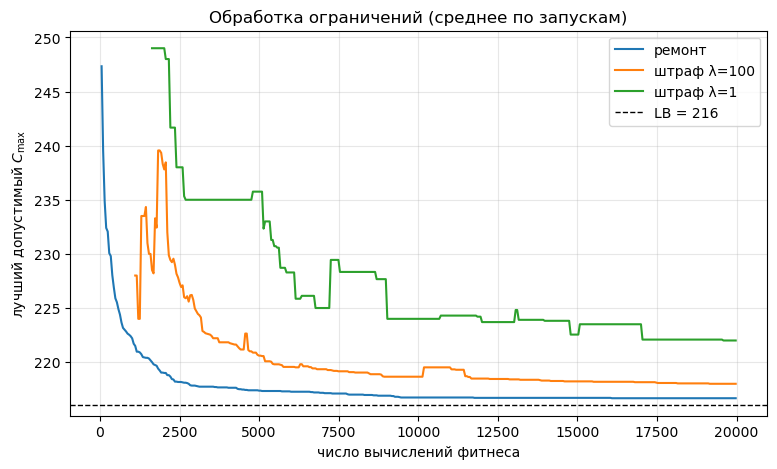

,best,mean,median,std,worst,feasible,gap_median_%,hit_LB,time_s
ремонт,216.0,216.666667,217.0,0.711159,218.0,1.0,0.462963,0.466667,4.196222
штраф λ=100,216.0,218.000000,217.0,2.148345,227.0,0.9,0.462963,0.066667,0.215998
штраф λ=1,217.0,222.000000,217.5,9.534626,249.0,0.4,0.694444,0.000000,0.209842


In [17]:
cons_table, cons_runs, cons_hist = compare("constraints", {
    "ремонт": BASE,
    "штраф λ=100": replace(BASE, constraints="penalty", lam=100),
    "штраф λ=1": replace(BASE, constraints="penalty", lam=1),
}, "Обработка ограничений (среднее по запускам)")
cons_table

### 3.2. Мутация: балансирующая и случайная

* Ремонт; меняется только мутация

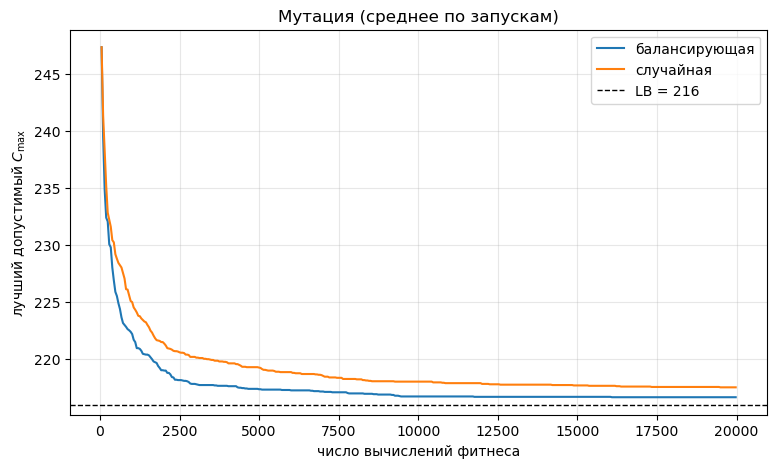

,best,mean,median,std,worst,feasible,gap_median_%,hit_LB,time_s
балансирующая,216.0,216.666667,217.0,0.711159,218.0,1.0,0.462963,0.466667,4.155198
случайная,216.0,217.533333,217.0,1.074255,220.0,1.0,0.462963,0.133333,4.302055


In [18]:
mut_table, mut_runs, mut_hist = compare("mutation", {
    "балансирующая": BASE,
    "случайная": replace(BASE, mutation="random"),
}, "Мутация (среднее по запускам)")
mut_table

### 3.3. Сравнение с LPT и случайным допустимым поиском

* Случайный поиск: тот же бюджет $20\,000$, те же seed

LPT: C_max = 228, нарушений V = 28
LPT + ремонт: C_max = 249, нарушений V = 5


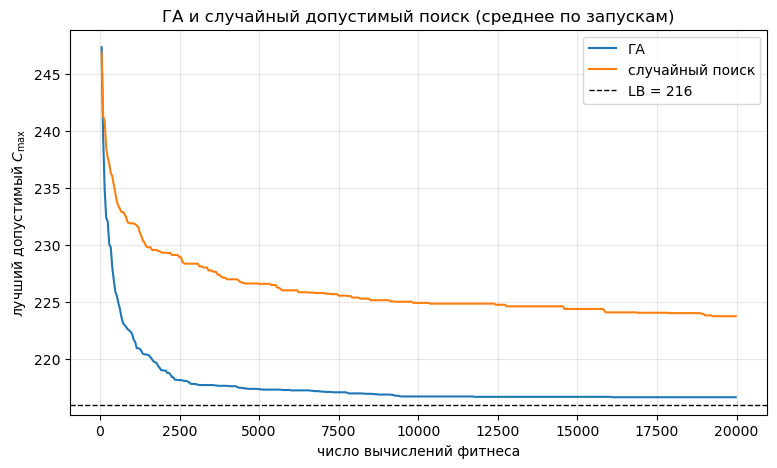

,best,mean,median,std,worst,feasible,gap_median_%,hit_LB,time_s
ГА,216.0,216.666667,217.0,0.711159,218.0,1.0,0.462963,0.466667,4.196222
случайный поиск,221.0,223.766667,224.0,1.832340,227.0,1.0,3.703704,0.000000,7.536465


In [19]:
x_lpt_rep = repair(x_lpt, inst, np.random.default_rng(0))
c_lpt, v_lpt, _ = evaluate(x_lpt, inst)
c_lpt_rep, v_lpt_rep, _ = evaluate(x_lpt_rep, inst)
print(f"LPT: C_max = {c_lpt[0]}, нарушений V = {v_lpt[0]}")
print(f"LPT + ремонт: C_max = {c_lpt_rep[0]}, нарушений V = {v_lpt_rep[0]}")

checkpoints = cons_hist["ремонт"][0]["evals"].to_numpy()
rs_runs, rs_hist = run_series(lambda s: run_random_search(inst, BASE.max_evals, s, checkpoints), N_RUNS, BASE_SEED)
rs_runs.to_csv(RESULTS / "runs_random_search.csv", index=False)

base_table = pd.DataFrame([summarize(cons_runs["ремонт"], inst, "ГА"), summarize(rs_runs, inst, "случайный поиск")])
base_table.to_csv(RESULTS / "summary_ga_vs_baselines.csv")
fig, ax = plt.subplots()
plot_convergence({"ГА": cons_hist["ремонт"], "случайный поиск": rs_hist},
                 "ГА и случайный допустимый поиск (среднее по запускам)", inst, ax=ax)
fig.savefig(RESULTS / "convergence_ga_vs_random.png", dpi=120, bbox_inches="tight")
plt.show()
base_table

### 3.4. Лучшее найденное решение

seed = 1001, C_max = 216, LB = 216


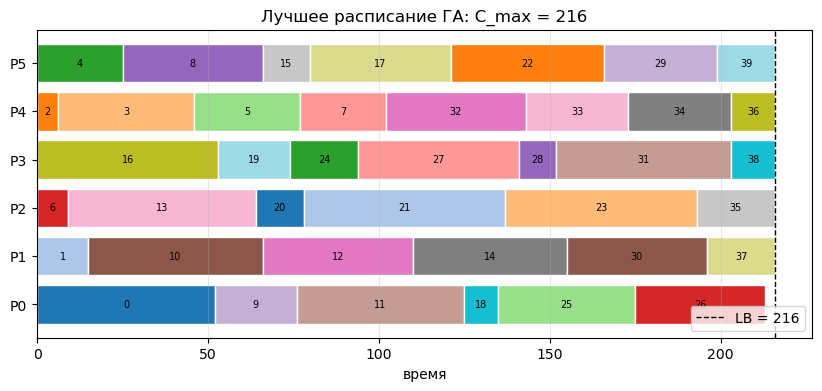

,задачи,L_j (время),M_j (память)
процессор,,,
0,"0, 9, 11, 18, 25, 26",213,76
1,"1, 10, 12, 14, 30, 37",216,74
2,"6, 13, 20, 21, 23, 35",216,73
3,"16, 19, 24, 27, 28, 31, 38",216,71
4,"2, 3, 5, 7, 32, 33, 34, 36",216,75
5,"4, 8, 15, 17, 22, 29, 39",216,70


In [20]:
r = cons_runs["ремонт"]
best_seed = int(r.loc[r.best_c.idxmin(), "seed"])
best = run_ga(BASE, inst, best_seed)
print(f"seed = {best_seed}, C_max = {best['best_c']}, LB = {inst['LB']}")
plot_schedule(best["best_x"], inst, f"Лучшее расписание ГА: C_max = {best['best_c']}", RESULTS / "best_schedule.png")
best_table = schedule_table(best["best_x"], inst)
best_table.to_csv(RESULTS / "best_schedule.csv")
best_table

## 4. Выводы

### 4.1. Результаты ($R = 30$, бюджет $2 \cdot 10^4$, $LB = C^* = 216$)

| метод | best | median | worst | допустимо | $C_{\max} = 216$ |
|---|---|---|---|---|---|
| ГА: ремонт + балансирующая | 216 | 217 | 218 | 100 % | 47 % |
| ГА: штраф λ = 100 | 216 | 217 | 227 | 90 % | 7 % |
| ГА: штраф λ = 1 | 217 | 217.5 | 249 | 40 % | 0 % |
| ГА: ремонт + случайная | 216 | 217 | 220 | 100 % | 13 % |
| случайный допустимый поиск | 221 | 224 | 227 | 100 % | 0 % |
| LPT | 228 | — | — | нет (28 нарушений) | — |
| LPT + ремонт | 249 | — | — | нет (5 нарушений) | — |

### 4.2. Ограничения: ремонт лучше штрафа

* Ремонт: допустимое решение в 100 % запусков, оптимум в 47 %
* **Штраф λ = 1 слишком слабый:** недопустимое решение с $V = 1$ и $C_{\max} \le 215$ имеет $F \le 216$ — не хуже допустимого с $C_{\max} = 216$ → ГА выгодно нарушать
* Гарантированно «любое допустимое лучше любого недопустимого», если $\lambda > \sum_i p_i - LB = 1077$; λ = 100 этого не гарантирует → 10 % запусков без допустимого решения
* Цена ремонта — время: $\approx 4.2$ с на запуск против $0.2$ с у штрафа при том же числе вычислений фитнеса
* На графике у штрафа скачки вверх: среднее берётся по запускам, где допустимое уже найдено; новый запуск приходит со своим первым, плохим решением

### 4.3. Мутация: балансирующая лучше случайной

* Оптимум в 47 % запусков против 13 %, худший 218 против 220
* Балансирующий перенос бьёт прямо в $C_{\max}$: разгружает самый загруженный процессор; случайная тратит мутации на процессоры, которые на $C_{\max}$ не влияют

### 4.4. Сравнение с базовыми методами

* **LPT при тесной памяти не находит допустимого решения**, даже после ремонта
* Случайный допустимый поиск: медиана 224 (+3.7 % к оптимуму) против 217 (+0.46 %) у ГА

### 4.5. Почему результат хороший

* Оптимум известен и доказан: $C^* = LB = 216$
* ГА: все 30 запусков $\le 218$ (не хуже оптимума на $0.9\%$), медиана $217$, ровно оптимум — в 14 из 30
* Лучшее расписание: 5 процессоров загружены ровно на 216, шестой на 213 — лучше не бывает
* **Ограничение:** при $n = 40$ точный ILP-решатель находит оптимум за $\sim 1$ с; ГА оправдан при большем $n$ и для ограничений, которые трудно записать линейно